# Part 3: Path-dependent exotic options

**The question:** what do we do when the payoff depends on the whole price path and the textbook formula is missing or wrong?

This is where Monte Carlo becomes genuinely necessary. The arithmetic Asian option has no closed form, so we price it by simulation, with a closely related option that does have one as a control variate. The barrier option has a closed form, but only if the barrier is watched continuously, and real contracts check it at a finite number of dates. We measure that bias and correct it.

**Conventions.** Monitoring dates are $t_i = iT/m$ for $i = 1, \dots, m$; $S_0$ itself is not a monitoring date. Between dates we use the exact GBM step, so the paths have no discretisation error. Paths move forward one date at a time and we keep only what the payoff needs, so memory does not grow with $m$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mc_utils as mc

mc.set_plot_style()
S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
H = 90.0  # barrier level
rng = np.random.default_rng(42)

## 1. Geometric Asian: an exact benchmark

An Asian call pays on the average price instead of the final price. The arithmetic average $A = \frac{1}{m}\sum_i S_{t_i}$ is a sum of lognormals, which has no tractable law. The geometric average $G = \big(\prod_i S_{t_i}\big)^{1/m}$ is different: $\ln G$ is an average of normal variables, so it is normal, and the price is a Black-Scholes-type formula:

$$\ln G \sim \mathcal{N}\big(\mu_G, \sigma_G^2\big), \quad \mu_G = \ln S_0 + \big(r - \tfrac{1}{2}\sigma^2\big)T\,\frac{m+1}{2m}, \quad \sigma_G^2 = \sigma^2 T\,\frac{(m+1)(2m+1)}{6m^2},$$

$$C_{\text{geo}} = e^{-rT}\Big(e^{\mu_G + \sigma_G^2/2}\,N(d_1) - K\,N(d_2)\Big), \qquad d_1 = \frac{\mu_G + \sigma_G^2 - \ln K}{\sigma_G}, \quad d_2 = d_1 - \sigma_G .$$

With $m = 1$ this is exactly Black-Scholes. We first check the simulation engine against this formula.

In [2]:
rows = []
for m in (12, 52, 252):
    res = mc.price_asian(S0, K, r, sigma, T, 200_000, m, average="geometric", rng=rng)
    exact = mc.geometric_asian_price(S0, K, r, sigma, T, m)
    rows.append(
        {
            "m": m,
            "MC price": res["price"],
            "std error": res["std_error"],
            "CI low": res["ci_low"],
            "CI high": res["ci_high"],
            "closed form": exact,
            "CI contains exact": res["ci_low"] <= exact <= res["ci_high"],
        }
    )
pd.DataFrame(rows).round(4)

,m,MC price,std error,CI low,CI high,closed form,CI contains exact
0,12,5.9608,0.0185,5.9245,5.9972,5.9402,True
1,52,5.6492,0.0175,5.6149,5.6835,5.6374,True
2,252,5.5808,0.0173,5.5468,5.6147,5.5655,True


All three intervals contain the closed form, for example 5.6492 (standard error 0.0175) against 5.6374 at $m = 52$. The path simulation and the averaging are correct, so we can trust the same engine where no formula exists.

## 2. Arithmetic Asian with the geometric control variate

On the same paths, take $X = e^{-rT}(A-K)^+$ and $Y = e^{-rT}(G-K)^+$, whose exact mean $C_{\text{geo}}$ is known. As in Part 2:

$$\hat V^{\text{CV}} = \frac{1}{n}\sum_{i=1}^{n}\Big(X_i - \hat\beta\,\big(Y_i - C_{\text{geo}}\big)\Big).$$

On every path the two averages of the same prices are very close ($A \ge G$ by the AM-GM inequality, with a small gap), so $\rho$ is almost 1. We price with $n = 50{,}000$, and measure the variance reduction factor from 200 independent runs at $n = 10{,}000$.

In [3]:
rows = []
for m in (12, 52, 252):
    params = dict(S0=S0, K=K, r=r, sigma=sigma, T=T, m=m)
    plain = mc.price_asian(**params, n=50_000, rng=rng)
    cv = mc.price_asian(**params, n=50_000, control_variate=True, rng=rng)
    var_plain = mc.price_variance(mc.price_asian, 200, rng, **params, n=10_000)
    var_cv = mc.price_variance(mc.price_asian, 200, rng, **params, n=10_000, control_variate=True)
    rows.append(
        {
            "m": m,
            "plain price": plain["price"],
            "plain std error": plain["std_error"],
            "CV price": cv["price"],
            "CV std error": cv["std_error"],
            "CV CI low": cv["ci_low"],
            "CV CI high": cv["ci_high"],
            "rho": f"{cv['rho']:.5f}",
            "predicted 1/(1-rho^2)": round(1 / (1 - cv["rho"] ** 2)),
            "measured VR factor": round(var_plain / var_cv),
        }
    )
pd.DataFrame(rows).round(4)

,m,plain price,plain std error,CV price,CV std error,CV CI low,CV CI high,rho,predicted 1/(1-rho^2),measured VR factor
0,12,6.2241,0.0384,6.1588,0.0011,6.1567,6.1609,0.99960,1246,1560
1,52,5.9068,0.0366,5.8544,0.0010,5.8525,5.8564,0.99962,1325,1323
2,252,5.7541,0.0355,5.7815,0.0010,5.7796,5.7835,0.99961,1296,1201


The control variate divides the standard error by about 36 (from 0.0366 to 0.0010 at $m = 52$), because $\rho$ is about 0.9996. The measured factors (1560, 1323, 1201) scatter around the predictions (1246, 1325, 1296). With 200 runs each variance is uncertain by about 10%, so their ratio is uncertain by about 14%: the honest summary is a variance reduction above 1,000, close to the 1,300 that theory predicts at every $m$.

## 3. Averaging lowers the price

We now vary the number of monitoring dates. With $m = 1$ the average is just $S_T$, so all three prices must coincide. As $m$ grows, $\sigma_G^2$ falls from $\sigma^2T$ towards $\sigma^2T/3$: the average moves less than the stock, so the option is worth less.

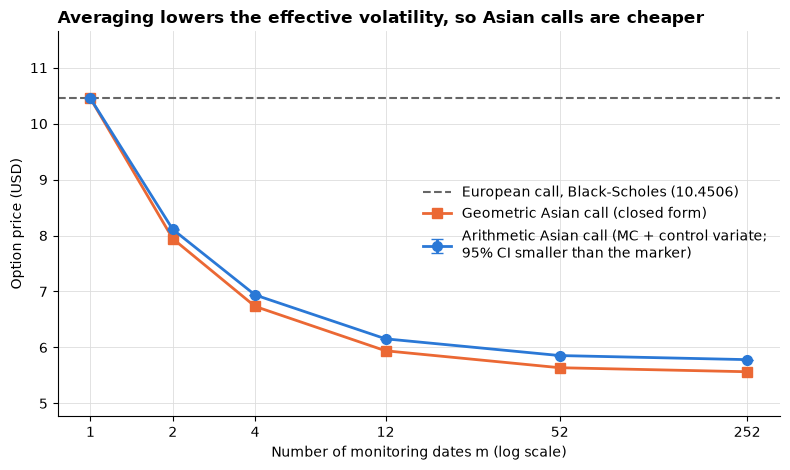

,m,arithmetic (MC + CV),std error,geometric (closed form),European (BS)
0,1,10.4506,0.0000,10.4506,10.4506
1,2,8.1097,0.0014,7.9434,10.4506
2,4,6.9383,0.0013,6.7335,10.4506
3,12,6.1540,0.0010,5.9402,10.4506
4,52,5.8548,0.0010,5.6374,10.4506
5,252,5.7820,0.0010,5.5655,10.4506


In [4]:
ms = [1, 2, 4, 12, 52, 252]
european = mc.bs_price(S0, K, r, sigma, T, "call")
rows = []
for m in ms:
    res = mc.price_asian(S0, K, r, sigma, T, 50_000, m, control_variate=True, rng=rng)
    rows.append(
        {
            "m": m,
            "arithmetic (MC + CV)": res["price"],
            "std error": res["std_error"],
            "geometric (closed form)": mc.geometric_asian_price(S0, K, r, sigma, T, m),
            "European (BS)": european,
        }
    )
asian = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(
    european,
    color=mc.GREY,
    linestyle="--",
    linewidth=1.5,
    label=f"European call, Black-Scholes ({european:.4f})",
)
ax.plot(
    ms,
    asian["geometric (closed form)"],
    color=mc.ORANGE,
    marker="s",
    markersize=7,
    label="Geometric Asian call (closed form)",
)
ax.errorbar(
    ms,
    asian["arithmetic (MC + CV)"],
    yerr=mc.Z_95 * asian["std error"],
    color=mc.BLUE,
    marker="o",
    markersize=7,
    capsize=4,
    label="Arithmetic Asian call (MC + control variate;\n95% CI smaller than the marker)",
)
ax.set_xscale("log")
ax.set_xticks(ms, [str(m) for m in ms])
ax.minorticks_off()
ax.set_xlabel("Number of monitoring dates m (log scale)")
ax.set_ylabel("Option price (USD)")
ax.set_ylim(asian["geometric (closed form)"].min() - 0.8, european + 1.2)
ax.set_title("Averaging lowers the effective volatility, so Asian calls are cheaper")
ax.legend(loc="center right")
fig.tight_layout()
fig.savefig("figures/06_asian_vs_monitoring.png")
plt.show()
asian.round(4)

At $m = 1$ all three prices coincide at 10.4506. The control variate is exact there, since both averages equal $S_T$ (standard error 0). The price then falls quickly: at $m = 52$ the arithmetic Asian is worth 5.8548, about 44% less than the European call. It stays above the geometric Asian (5.6374), as the AM-GM inequality requires.

## 4. Barrier option: the discrete-monitoring bias

A down-and-out call pays like a vanilla call, unless the stock falls to the barrier $H$, in which case it dies. A down-and-in call is the opposite, so on every path knock-in + knock-out = vanilla.

The closed form (Reiner-Rubinstein, for $H \le K$) assumes the barrier is watched at every instant. With $\lambda = \frac{r + \sigma^2/2}{\sigma^2}$ and $y = \frac{\ln(H^2/(S_0K))}{\sigma\sqrt{T}} + \lambda\sigma\sqrt{T}$:

$$C_{\text{DI}} = S_0\Big(\frac{H}{S_0}\Big)^{2\lambda}N(y) - Ke^{-rT}\Big(\frac{H}{S_0}\Big)^{2\lambda-2}N\big(y - \sigma\sqrt{T}\big), \qquad C_{\text{DO}} = C_{\text{BS}} - C_{\text{DI}} .$$

Real contracts check the barrier at $m$ dates, so a path can dip below $H$ between two dates and survive. The discrete option is knocked out **less** often and is worth **more**: the continuous formula understates its price. Broadie, Glasserman and Kou (1997) showed that the continuous formula still works if the barrier is moved away from the spot:

$$H_{\text{eff}} = H\,e^{-\beta\sigma\sqrt{T/m}}, \qquad \beta = -\frac{\zeta(1/2)}{\sqrt{2\pi}} \approx 0.5826,$$

where $\zeta$ is the Riemann zeta function. We take $H = 90$, $K = 100$, $n = 200{,}000$ paths.

Fitted log-log slope of |continuous - MC| against m: -0.4570 (theory: -0.5)


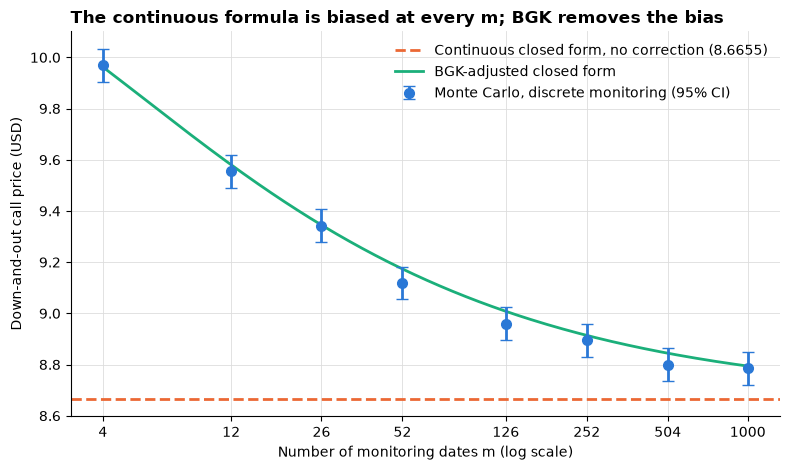

,m,MC price,std error,continuous formula,bias (continuous - MC),BGK formula,bias (BGK - MC),BGK in CI
0,4,9.9686,0.0330,8.6655,-1.3032,9.9626,-0.0061,True
1,12,9.5557,0.0330,8.6655,-0.8902,9.5802,0.0246,True
2,26,9.3427,0.0330,8.6655,-0.6772,9.3450,0.0023,True
3,52,9.1186,0.0327,8.6655,-0.4531,9.1736,0.0550,True
4,126,8.9602,0.0328,8.6655,-0.2947,9.0080,0.0478,True
5,252,8.8941,0.0328,8.6655,-0.2286,8.9139,0.0199,True
6,504,8.7996,0.0327,8.6655,-0.1341,8.8443,0.0447,True
7,1000,8.7860,0.0327,8.6655,-0.1205,8.7941,0.0081,True


In [5]:
ms = [4, 12, 26, 52, 126, 252, 504, 1000]
continuous = mc.barrier_closed_form(S0, K, H, r, sigma, T)
rows = []
for m in ms:
    res = mc.price_barrier(S0, K, H, r, sigma, T, 200_000, m, rng=rng)
    bgk = mc.barrier_closed_form(S0, K, mc.bgk_barrier(H, sigma, T, m), r, sigma, T)
    rows.append(
        {
            "m": m,
            "MC price": res["price"],
            "std error": res["std_error"],
            "continuous formula": continuous,
            "bias (continuous - MC)": continuous - res["price"],
            "BGK formula": bgk,
            "bias (BGK - MC)": bgk - res["price"],
            "BGK in CI": res["ci_low"] <= bgk <= res["ci_high"],
        }
    )
barrier = pd.DataFrame(rows)

# The bias of the continuous formula should fall like 1 / sqrt(m).
slope = np.polyfit(np.log(barrier["m"]), np.log(barrier["bias (continuous - MC)"].abs()), 1)[0]
print(f"Fitted log-log slope of |continuous - MC| against m: {slope:.4f} (theory: -0.5)")

m_grid = np.geomspace(ms[0], ms[-1], 200)
bgk_curve = [
    mc.barrier_closed_form(S0, K, mc.bgk_barrier(H, sigma, T, m), r, sigma, T) for m in m_grid
]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(
    continuous,
    color=mc.ORANGE,
    linestyle="--",
    label=f"Continuous closed form, no correction ({continuous:.4f})",
)
ax.plot(m_grid, bgk_curve, color=mc.AQUA, label="BGK-adjusted closed form")
ax.errorbar(
    ms,
    barrier["MC price"],
    yerr=mc.Z_95 * barrier["std error"],
    color=mc.BLUE,
    marker="o",
    markersize=7,
    capsize=4,
    linestyle="none",
    label="Monte Carlo, discrete monitoring (95% CI)",
)
ax.set_xscale("log")
ax.set_xticks(ms, [str(m) for m in ms])
ax.minorticks_off()
ax.set_xlabel("Number of monitoring dates m (log scale)")
ax.set_ylabel("Down-and-out call price (USD)")
ax.set_title("The continuous formula is biased at every m; BGK removes the bias")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figures/07_barrier_monitoring_bias.png")
plt.show()
barrier.round(4)

The continuous formula is below the Monte Carlo price at every $m$, as expected. Even with daily monitoring ($m = 252$) it is off by -0.2286, about 7 standard errors. The BGK price is inside the 95% interval at all eight frequencies. The fitted slope is -0.4570 rather than -0.5, because $1/\sqrt{m}$ is only the leading term and the points at large $m$ are noisy: there the bias is only about 4 standard errors.

## 5. Price against the barrier level

With daily monitoring ($m = 252$, $n = 100{,}000$), we move the barrier from far below the spot to just under it.

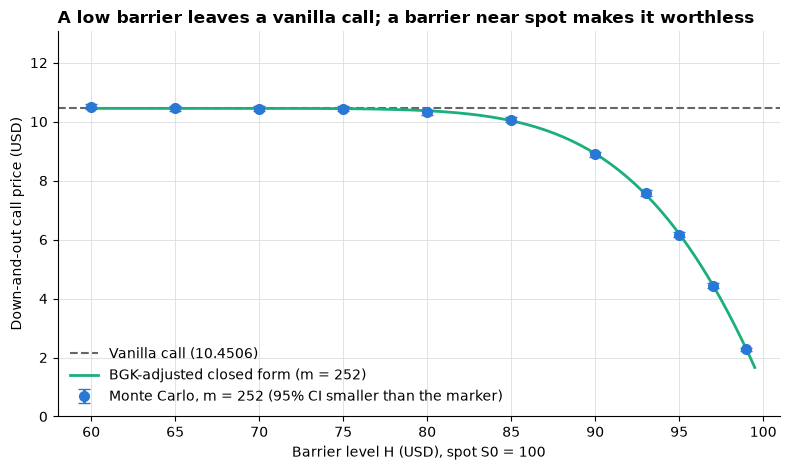

,H,MC price,std error,BGK formula,BGK - MC,BGK in CI
0,60,10.5049,0.0467,10.4506,-0.0544,True
1,65,10.4515,0.0465,10.4506,-0.0009,True
2,70,10.4420,0.0465,10.4499,0.0078,True
3,75,10.4419,0.0465,10.4407,-0.0012,True
4,80,10.3190,0.0466,10.3706,0.0517,True
5,85,10.0655,0.0469,10.0322,-0.0334,True
6,90,8.8912,0.0463,8.9139,0.0227,True
7,93,7.5814,0.0451,7.5340,-0.0474,True
8,95,6.1725,0.0425,6.1960,0.0235,True
9,97,4.4423,0.0380,4.4598,0.0175,True


In [6]:
m = 252
levels = [60, 65, 70, 75, 80, 85, 90, 93, 95, 97, 99]
vanilla = mc.bs_price(S0, K, r, sigma, T, "call")
rows = []
for level in levels:
    res = mc.price_barrier(S0, K, float(level), r, sigma, T, 100_000, m, rng=rng)
    bgk = mc.barrier_closed_form(S0, K, mc.bgk_barrier(level, sigma, T, m), r, sigma, T)
    rows.append(
        {
            "H": level,
            "MC price": res["price"],
            "std error": res["std_error"],
            "BGK formula": bgk,
            "BGK - MC": bgk - res["price"],
            "BGK in CI": res["ci_low"] <= bgk <= res["ci_high"],
        }
    )
by_level = pd.DataFrame(rows)

H_grid = np.linspace(60, 99.5, 300)
curve = [mc.barrier_closed_form(S0, K, mc.bgk_barrier(h, sigma, T, m), r, sigma, T) for h in H_grid]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(
    vanilla, color=mc.GREY, linestyle="--", linewidth=1.5, label=f"Vanilla call ({vanilla:.4f})"
)
ax.plot(H_grid, curve, color=mc.AQUA, label=f"BGK-adjusted closed form (m = {m})")
ax.errorbar(
    levels,
    by_level["MC price"],
    yerr=mc.Z_95 * by_level["std error"],
    color=mc.BLUE,
    marker="o",
    markersize=7,
    capsize=4,
    linestyle="none",
    label=f"Monte Carlo, m = {m} (95% CI smaller than the marker)",
)
ax.set_xlabel("Barrier level H (USD), spot S0 = 100")
ax.set_ylabel("Down-and-out call price (USD)")
ax.set_xlim(58, 101)
ax.set_ylim(0, vanilla * 1.25)
ax.set_title("A low barrier leaves a vanilla call; a barrier near spot makes it worthless")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figures/08_barrier_price_vs_level.png")
plt.show()
by_level.round(4)

BGK stays inside the Monte Carlo interval for all 11 barriers. Far below the spot, the barrier is almost never hit and the option is a vanilla call (10.4506 at $H = 60$ on the BGK curve). Near the spot, most paths are knocked out and the price collapses, to 2.2818 at $H = 99$.

## 6. In-out parity on the same paths

With the same seed, the knock-out and the knock-in see exactly the same paths. On every path exactly one of them pays the vanilla payoff, so their prices must add up to the vanilla price on those paths.

In [7]:
out = mc.price_barrier(S0, K, H, r, sigma, T, 100_000, 52, "down-and-out", rng=42)
knock_in = mc.price_barrier(S0, K, H, r, sigma, T, 100_000, 52, "down-and-in", rng=42)
total = out["price"] + knock_in["price"]
print(f"down-and-out {out['price']:.6f} + down-and-in {knock_in['price']:.6f} = {total:.6f}")
print(f"vanilla on the same paths: {out['vanilla']:.6f}, difference {total - out['vanilla']:.2e}")

down-and-out 9.286462 + down-and-in 1.270202 = 10.556664
vanilla on the same paths: 10.556664, difference 1.78e-15


The two prices add up to the vanilla on the same paths; the difference of 1.78e-15 is floating-point rounding. This vanilla is a Monte Carlo estimate on these 100,000 paths, not the Black-Scholes price: parity holds path by path, whatever the sampling noise.

## 7. How accurate is BGK really?

With 200,000 paths the standard error (about 0.033) is as large as the error we are trying to measure, so the table of section 4 cannot say whether BGK is exact or just close. We repeat three cases with 4,000,000 paths, which divides the standard error by about 4.5.

In [8]:
rows = []
for m in (4, 12, 52):
    res = mc.price_barrier(S0, K, H, r, sigma, T, 4_000_000, m, rng=rng)
    bgk = mc.barrier_closed_form(S0, K, mc.bgk_barrier(H, sigma, T, m), r, sigma, T)
    rows.append(
        {
            "m": m,
            "MC price": res["price"],
            "std error": res["std_error"],
            "BGK formula": bgk,
            "bias (BGK - MC)": bgk - res["price"],
            "BGK bias in std errors": (bgk - res["price"]) / res["std_error"],
            "bias (continuous - MC)": continuous - res["price"],
        }
    )
pd.DataFrame(rows).round(4)

,m,MC price,std error,BGK formula,bias (BGK - MC),BGK bias in std errors,bias (continuous - MC)
0,4,9.9714,0.0074,9.9626,-0.0089,-1.2001,-1.3060
1,12,9.5734,0.0074,9.5802,0.0068,0.9210,-0.9080
2,52,9.1719,0.0074,9.1736,0.0017,0.2285,-0.5064


With a standard error of 0.0074, the BGK error is below 0.01 at all three frequencies (-0.0089, +0.0068, +0.0017), about one standard error or less. So BGK is accurate even with quarterly monitoring ($m = 4$), while the bias of the uncorrected formula is large and unmistakable: -1.3060, -0.9080 and -0.5064. Between $m = 4$ and $m = 52$ this bias falls by a factor of about 2.6, less than the 3.6 that $1/\sqrt{m}$ would give: the price is a curved function of the barrier (see the previous figure), so the $1/\sqrt{m}$ law only holds for small shifts.

## Key takeaways

- The arithmetic Asian has no closed form, but a closely related option that has one is an excellent control variate: variance divided by 1323 at $m = 52$ ($\rho$ = 0.99962).
- Averaging lowers the volatility, so an Asian call is much cheaper than a European call: 5.8548 against 10.4506 at $m = 52$.
- The continuous barrier formula understates a discretely monitored down-and-out by 0.5064 at $m = 52$. The BGK shift of the barrier reduces this error to 0.0017.